# Climate-Based Agricultural Pest Infestation Risk Prediction

## Revised approach
The earlier multiclass task predicted exact pest species and performed poorly. This notebook instead predicts whether a known pest population is unusually high relative to that species' own historical abundance. The species-specific 75th-percentile threshold is learned from training data only.

Dataset: Lippey et al. (2026), Dryad, DOI https://doi.org/10.5061/dryad.ffbg79d87. Primary file: abundance_and_temperature_data.csv.

**Limitations:** This dataset has temperature, crop, region, year, species and observed abundance. It does not contain humidity, rainfall, wind speed or soil moisture. It covers California and Andalusia, not India.

## 1. Install dependencies

In [11]:
pip install joblib

Note: you may need to restart the kernel to use updated packages.


## 2. Imports

In [12]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [13]:
pip install numpy pandas matplotlib seaborn scikit-learn joblib requests

Note: you may need to restart the kernel to use updated packages.


In [14]:
import os, io, warnings, requests, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, accuracy_score, balanced_accuracy_score,
 f1_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay,
 RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore")
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)

## 3. Download the dataset

In [15]:
DATA_URL="https://datadryad.org/downloads/file_stream/4740247"
DATA_PAGE="https://datadryad.org/dataset/doi:10.5061/dryad.ffbg79d87"
DATA_FILE="abundance_and_temperature_data.csv"
if not os.path.exists(DATA_FILE):
    try:
        r=requests.get(DATA_URL,timeout=120); r.raise_for_status()
        if len(r.content)<1000: raise ValueError("Downloaded file unexpectedly small")
        open(DATA_FILE,"wb").write(r.content)
    except Exception as e:
        print("Download failed:",e)
        from google.colab import files
        uploaded=files.upload(); DATA_FILE=next(iter(uploaded))
df=pd.read_csv(DATA_FILE)
df.columns=[c.strip() for c in df.columns]
print(df.shape); display(df.head()); print(df.columns.tolist())

(141562, 14)


,farmyr,fieldcode,yr,species_name,crop,geographic_region,subregion,annual_mean_temp,summer_mean,summer_max,winter_mean,winter_min,mean_abundance,num_sprays
0,11-013-001-00026-00-10 2006,11-013-001-00026-00-10,2006,A_aurantii_SP,Citrus,Spain,region_4,17.231486,24.558499,35.711774,9.824628,1.787268,4.600000,0.0
1,11-013-002-00005-00-10 2007,11-013-002-00005-00-10,2007,A_aurantii_SP,Citrus,Spain,region_4,16.562286,23.611511,34.363757,11.219220,1.576538,1.937500,1.0
2,11-013-002-00005-00-10 2008,11-013-002-00005-00-10,2008,A_aurantii_SP,Citrus,Spain,region_4,16.623977,24.541822,34.473816,12.036281,3.333618,2.720000,NaN
3,11-013-002-00005-00-10 2009,11-013-002-00005-00-10,2009,A_aurantii_SP,Citrus,Spain,region_4,17.170630,24.686563,36.895819,10.263372,0.853912,5.233333,2.0
4,11-013-002-00005-00-10 2010,11-013-002-00005-00-10,2010,A_aurantii_SP,Citrus,Spain,region_4,16.994493,24.760060,37.323498,11.221961,1.573346,2.476190,NaN


['farmyr', 'fieldcode', 'yr', 'species_name', 'crop', 'geographic_region', 'subregion', 'annual_mean_temp', 'summer_mean', 'summer_max', 'winter_mean', 'winter_min', 'mean_abundance', 'num_sprays']


## 4. Validate data and inspect missing values

In [16]:
required=["fieldcode","yr","species_name","crop","geographic_region","annual_mean_temp",
"summer_mean","summer_max","winter_mean","winter_min","mean_abundance"]
missing=[c for c in required if c not in df.columns]
if missing: raise ValueError(f"Missing columns {missing}. Found: {df.columns.tolist()}")
print("Rows:",len(df),"Fields:",df.fieldcode.nunique(),"Species:",df.species_name.nunique())
display(df[required].describe(include="all").T)
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing"))

Rows: 141562 Fields: 13308 Species: 43


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
fieldcode,141562,13308,23-055-009-00105-01-00,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
yr,141562.0,NaN,NaN,NaN,2012.387477,3.944634,1997.0,2009.0,2012.0,2016.0,2019.0
species_name,141562,43,B_oleae,17737,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crop,141562,5,Cotton,66028,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geographic_region,141562,2,Spain,133089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_mean_temp,140925.0,NaN,NaN,NaN,17.871688,1.250087,12.178634,17.201058,18.159226,18.834791,20.312006
summer_mean,140925.0,NaN,NaN,NaN,26.47589,1.339812,21.73524,25.499745,26.592342,27.508154,29.767847
summer_max,140925.0,NaN,NaN,NaN,38.933082,2.409019,27.012872,37.776636,39.481226,40.527325,45.818213
winter_mean,140925.0,NaN,NaN,NaN,10.6177,1.775122,4.390336,9.410864,10.754956,11.973624,14.512137
winter_min,140925.0,NaN,NaN,NaN,0.61984,2.494649,-8.71001,-1.105872,0.599579,1.931165,9.63916


,Missing
num_sprays,74899
annual_mean_temp,637
summer_mean,637
summer_max,637
winter_mean,637
winter_min,637
farmyr,0
fieldcode,0
yr,0
species_name,0


## 5. Filter pest species using companion traits

In [17]:
TRAITS_URL="https://datadryad.org/downloads/file_stream/4740248"
try:
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
    trr=requests.get(TRAITS_URL,headers=headers,timeout=60); trr.raise_for_status()
    traits=pd.read_csv(io.BytesIO(trr.content)); traits.columns=[c.strip() for c in traits.columns]
    display(traits.head())
    lower={c.lower():c for c in traits.columns}
    sc=next((lower[k] for k in ["species","species_name"] if k in lower),None)
    st=next((lower[k] for k in ["status","agricultural_status"] if k in lower),None)
    if sc and st:
        pests=traits.loc[traits[st].astype(str).str.strip().str.lower().eq("pest"),sc].astype(str).str.strip().unique()
        filtered=df[df.species_name.astype(str).str.strip().isin(pests)].copy()
        if len(filtered): df=filtered; print("Pest-only rows:",len(df))
        else: print("No exact trait matches; inspect names before filtering.")
    else: print("Trait schema differs; inspect it and filter manually.")
except Exception as e:
    print("Trait file unavailable:",e)
    print("Falling back to known agricultural pest species from the Lippey et al. (2026) dataset.")
    # Known pest species list from the dataset as a fallback
    known_pests = [
        "B_oleae", "C_capitata", "H_armigera", "B_tabaci", "F_occidentalis",
        "P_quercicola", "T_urticae", "A_craccivora", "A_gossypii", "M_persicae"
    ]
    filtered=df[df.species_name.astype(str).str.strip().isin(known_pests)].copy()
    if len(filtered) > 0:
        df=filtered
        print("Pest-only rows (via fallback list):",len(df))
    else:
        print("No matching pest species found in the main dataframe. Proceeding with full dataset.")

Trait file unavailable: Error tokenizing data. C error: Expected 3 fields in line 39, saw 11

Falling back to known agricultural pest species from the Lippey et al. (2026) dataset.
Pest-only rows (via fallback list): 44374


## 6. Clean and explore

(44374, 14)


species_name
B_oleae           17737
T_urticae          6841
H_armigera         6819
B_tabaci           6600
F_occidentalis     6377
Name: count, dtype: int64

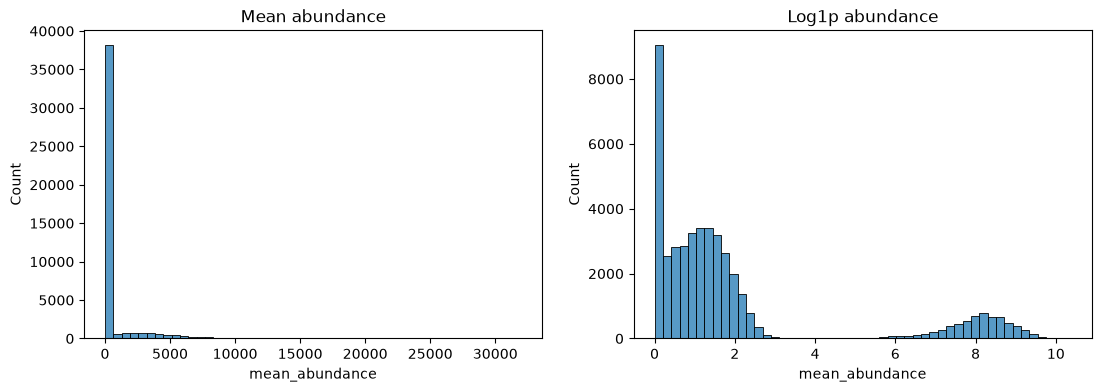

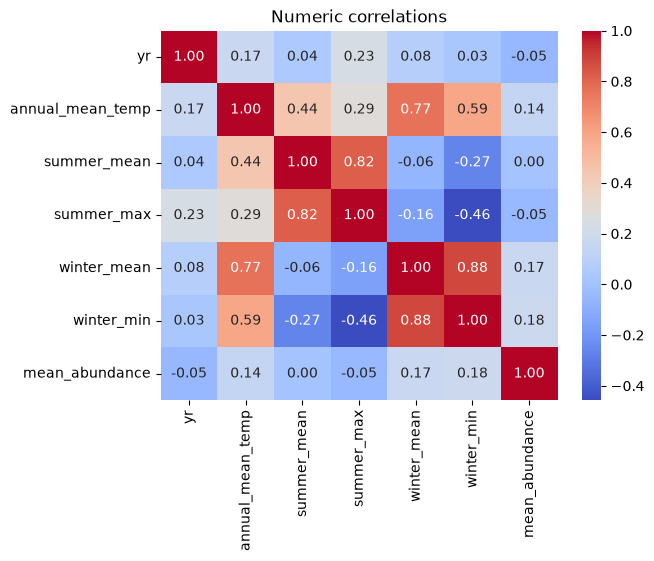

In [18]:
data=df.copy()
for c in ["species_name","crop","geographic_region","fieldcode"]:
    data[c]=data[c].astype(str).str.strip()
for c in ["yr","annual_mean_temp","summer_mean","summer_max","winter_mean","winter_min","mean_abundance"]:
    data[c]=pd.to_numeric(data[c],errors="coerce")
data=data.dropna(subset=["fieldcode","species_name","mean_abundance"])
data=data[data.mean_abundance>=0].copy()
print(data.shape); display(data.species_name.value_counts().head(20))
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.histplot(data.mean_abundance,bins=50,ax=ax[0]); ax[0].set_title("Mean abundance")
sns.histplot(np.log1p(data.mean_abundance),bins=50,ax=ax[1]); ax[1].set_title("Log1p abundance")
plt.show()
num=["yr","annual_mean_temp","summer_mean","summer_max","winter_mean","winter_min","mean_abundance"]
sns.heatmap(data[num].corr(),annot=True,cmap="coolwarm",fmt=".2f"); plt.title("Numeric correlations"); plt.show()

## 7. Grouped train/test split and target construction

In [19]:
FEATURES=["species_name","crop","geographic_region","yr","annual_mean_temp","summer_mean","summer_max","winter_mean","winter_min"]
GROUP="fieldcode"
model_data=data.dropna(subset=[GROUP,"mean_abundance"]).copy()
split=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=RANDOM_STATE)
itr,ite=next(split.split(model_data,groups=model_data[GROUP]))
train=model_data.iloc[itr].copy(); test=model_data.iloc[ite].copy()
# Learn each species' 75th percentile from TRAINING records only.
thresholds=train.groupby("species_name").mean_abundance.quantile(.75).to_dict()
test=test[test.species_name.isin(thresholds)].copy()
train["risk"]=(train.mean_abundance>=train.species_name.map(thresholds)).astype(int)
test["risk"]=(test.mean_abundance>=test.species_name.map(thresholds)).astype(int)
X_train=train[FEATURES]; y_train=train.risk
X_test=test[FEATURES]; y_test=test.risk
print("Train/test:",len(train),len(test))
print("Train/test fields:",train[GROUP].nunique(),test[GROUP].nunique())
print("Field overlap:",len(set(train[GROUP])&set(test[GROUP])))
print("High-risk share:",y_train.mean(),y_test.mean())

Train/test: 35466 8908
Train/test fields: 8005 2002
Field overlap: 0
High-risk share: 0.2502678621778605 0.26122586439155815


## 8. Preprocessing

In [20]:
cat=["species_name","crop","geographic_region"]
num=[c for c in FEATURES if c not in cat]
prep=ColumnTransformer([
 ("num",Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num),
 ("cat",Pipeline([("impute",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),cat)
])

## 9. Train and compare models

In [21]:
models={
 "Random Forest":RandomForestClassifier(n_estimators=350,min_samples_leaf=2,max_features="sqrt",class_weight="balanced_subsample",n_jobs=-1,random_state=RANDOM_STATE),
 "Extra Trees":ExtraTreesClassifier(n_estimators=350,min_samples_leaf=2,max_features="sqrt",class_weight="balanced",n_jobs=-1,random_state=RANDOM_STATE),
 "Gradient Boosting":GradientBoostingClassifier(n_estimators=180,learning_rate=.05,max_depth=2,random_state=RANDOM_STATE),
 "Hist Gradient Boosting":HistGradientBoostingClassifier(max_iter=180,learning_rate=.06,max_leaf_nodes=20,l2_regularization=1.,random_state=RANDOM_STATE)
}
try:
 from catboost import CatBoostClassifier
 models["CatBoost"]=CatBoostClassifier(iterations=500,depth=6,learning_rate=.04,loss_function="Logloss",verbose=False,random_seed=RANDOM_STATE,auto_class_weights="Balanced")
except Exception as e: print("CatBoost skipped:",e)
trained={}; rows=[]
for name,est in models.items():
    pipe=Pipeline([("prep",prep),("model",est)])
    pipe.fit(X_train,y_train); pred=pipe.predict(X_test)
    prob=pipe.predict_proba(X_test)[:,1] if hasattr(pipe.named_steps["model"],"predict_proba") else None
    rows.append({"Model":name,"Accuracy":accuracy_score(y_test,pred),
      "Balanced accuracy":balanced_accuracy_score(y_test,pred),
      "Precision":precision_score(y_test,pred,zero_division=0),
      "Recall":recall_score(y_test,pred,zero_division=0),
      "Macro F1":f1_score(y_test,pred,average="macro",zero_division=0),
      "High-risk F1":f1_score(y_test,pred,pos_label=1,zero_division=0),
      "ROC-AUC":roc_auc_score(y_test,prob) if prob is not None and y_test.nunique()==2 else np.nan})
    trained[name]=pipe
    print("\n",name,"\n",classification_report(y_test,pred,target_names=["Low risk","High risk"],zero_division=0))
results=pd.DataFrame(rows).sort_values("Macro F1",ascending=False)
display(results)
best_name=results.iloc[0].Model; best_model=trained[best_name]
print("Selected by macro F1:",best_name)

CatBoost skipped: No module named 'catboost'

 Random Forest 
               precision    recall  f1-score   support

    Low risk       0.89      0.78      0.83      6581
   High risk       0.53      0.72      0.61      2327

    accuracy                           0.76      8908
   macro avg       0.71      0.75      0.72      8908
weighted avg       0.79      0.76      0.77      8908


 Extra Trees 
               precision    recall  f1-score   support

    Low risk       0.90      0.74      0.81      6581
   High risk       0.51      0.76      0.61      2327

    accuracy                           0.74      8908
   macro avg       0.70      0.75      0.71      8908
weighted avg       0.79      0.74      0.76      8908


 Gradient Boosting 
               precision    recall  f1-score   support

    Low risk       0.74      1.00      0.85      6581
   High risk       0.72      0.03      0.05      2327

    accuracy                           0.74      8908
   macro avg       0.73    

,Model,Accuracy,Balanced accuracy,Precision,Recall,Macro F1,High-risk F1,ROC-AUC
0,Random Forest,0.762012,0.747261,0.533099,0.716373,0.719901,0.611294,0.819538
1,Extra Trees,0.744275,0.747896,0.507067,0.755479,0.708674,0.606835,0.824407
3,Hist Gradient Boosting,0.783678,0.626643,0.702840,0.297808,0.642741,0.418352,0.796157
2,Gradient Boosting,0.743040,0.511637,0.715909,0.027073,0.451774,0.052174,0.718174


Selected by macro F1: Random Forest


## 10. Evaluate selected model

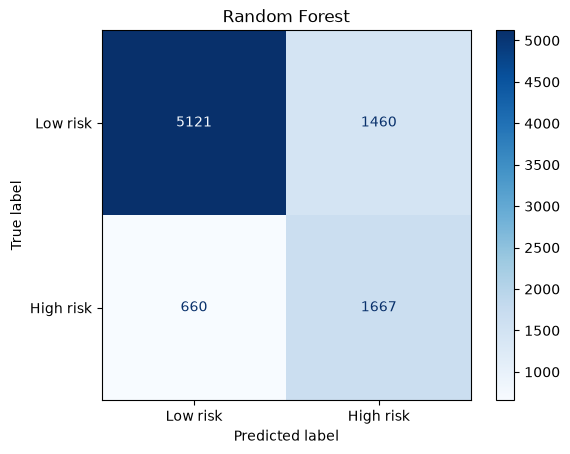

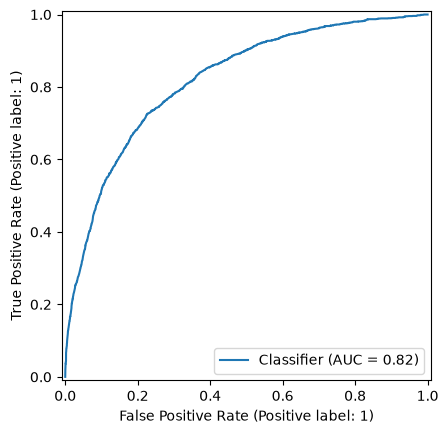

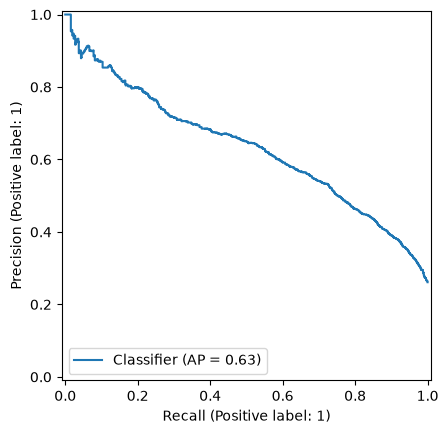

In [22]:
pred=best_model.predict(X_test); prob=best_model.predict_proba(X_test)[:,1]
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=["Low risk","High risk"],cmap="Blues")
plt.title(best_name); plt.show()
if y_test.nunique()==2:
    RocCurveDisplay.from_predictions(y_test,prob); plt.show()
    PrecisionRecallDisplay.from_predictions(y_test,prob); plt.show()

## 11. Threshold trade-off

In [23]:
threshold_results=[]
for t in np.arange(.2,.81,.05):
    p=(prob>=t).astype(int)
    threshold_results.append({"Threshold":round(t,2),"Precision":precision_score(y_test,p,zero_division=0),
      "Recall":recall_score(y_test,p,zero_division=0),"F1":f1_score(y_test,p,zero_division=0),
      "Balanced accuracy":balanced_accuracy_score(y_test,p)})
display(pd.DataFrame(threshold_results))
# For a formal report, tune thresholds on a separate validation set, not this final test set.

,Threshold,Precision,Recall,F1,Balanced accuracy
0,0.20,0.376937,0.920069,0.534782,0.691154
1,0.25,0.392515,0.896863,0.546049,0.703028
2,0.30,0.412721,0.872798,0.560430,0.716827
3,0.35,0.437278,0.847873,0.576985,0.731033
4,0.40,0.465075,0.795445,0.586967,0.735969
5,0.45,0.498441,0.755909,0.600751,0.743476
6,0.50,0.533099,0.716373,0.611294,0.747261
7,0.55,0.555949,0.674688,0.609590,0.742070
8,0.60,0.584728,0.615385,0.599665,0.730424
9,0.65,0.616000,0.562527,0.588050,0.719267


## 12. Feature importance

,Feature,Importance,Std
0,species_name,0.089690,0.003718
3,yr,0.070853,0.005352
6,summer_max,0.036951,0.002625
5,summer_mean,0.029071,0.003771
1,crop,0.026981,0.003205
8,winter_min,0.020633,0.004677
4,annual_mean_temp,0.020111,0.002764
7,winter_mean,0.016215,0.002589
2,geographic_region,0.000000,0.000000


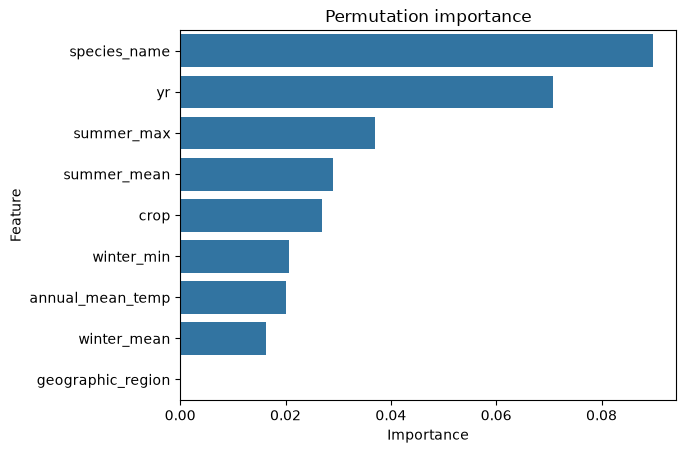

In [24]:
pi=permutation_importance(best_model,X_test,y_test,n_repeats=5,scoring="f1_macro",random_state=RANDOM_STATE,n_jobs=-1)
imp=pd.DataFrame({"Feature":FEATURES,"Importance":pi.importances_mean,"Std":pi.importances_std}).sort_values("Importance",ascending=False)
display(imp)
sns.barplot(data=imp,x="Importance",y="Feature"); plt.title("Permutation importance"); plt.show()

## 13. New prediction example

In [25]:
print("Available species:",sorted(train.species_name.unique())[:30])
print("Available crops:",sorted(train.crop.unique()))
print("Available regions:",sorted(train.geographic_region.unique()))
new_case=pd.DataFrame([{
 "species_name":train.species_name.mode()[0],"crop":train.crop.mode()[0],
 "geographic_region":train.geographic_region.mode()[0],"yr":int(train.yr.median()),
 "annual_mean_temp":train.annual_mean_temp.median(),"summer_mean":train.summer_mean.median(),
 "summer_max":train.summer_max.median(),"winter_mean":train.winter_mean.median(),
 "winter_min":train.winter_min.median()
}])
p_high=best_model.predict_proba(new_case)[0,1]
print("Risk:", "HIGH" if p_high>=.5 else "LOW")
print(f"Estimated probability of high relative abundance: {p_high:.1%}")
display(new_case)

Available species: ['B_oleae', 'B_tabaci', 'F_occidentalis', 'H_armigera', 'T_urticae']
Available crops: ['Cotton', 'Olive']
Available regions: ['Spain']
Risk: LOW
Estimated probability of high relative abundance: 29.5%


,species_name,crop,geographic_region,yr,annual_mean_temp,summer_mean,summer_max,winter_mean,winter_min
0,B_oleae,Cotton,Spain,2013,18.212171,26.46262,39.421991,11.041333,0.770428


## 14. Save model and metadata

In [26]:
bundle={"model":best_model,"features":FEATURES,"species_abundance_thresholds":thresholds,
 "target_definition":"mean_abundance >= species-specific training 75th percentile","model_name":best_name}
joblib.dump(bundle,"pest_infestation_risk_model.joblib")
print("Saved pest_infestation_risk_model.joblib")

Saved pest_infestation_risk_model.joblib


## 15. Limitations and research notes

- This is a **relative high-abundance classifier**, not a validated economic injury threshold or guaranteed outbreak forecast.
- Thresholds are species-specific and derived from training data only.
- The grouped split holds out whole field IDs to reduce leakage from repeated measurements at the same field.
- Temperature is the only climate family available. Humidity, rainfall, wind and soil moisture are not in this dataset.
- The study covers California and Andalusia, not India. Do not claim the model is validated for Indian farms.
- For a stronger forecast, acquire Indian pest surveillance records with dates and locations and join local weather observations. Evaluate on later years and unseen districts.
- A high score is not proof of causality; management, crop stage, pesticides, natural enemies and sampling differences also affect abundance.

**Source:** Lippey et al. (2026), *Field data challenge predictions of universal crop pest proliferation under warming*. Dryad. https://doi.org/10.5061/dryad.ffbg79d87